# 04 · PCA and UMAP

Maths unit **M4**. Read `viz/projection.py` and `jobs/select.run_pca`.

PCA keeps the directions along which the images vary most; UMAP squashes what is left onto a plane while keeping neighbours together. This notebook shows how much variance PCA keeps for each model, draws both maps from the cached projections (`python -m visualtaste.jobs.project`), and checks how well UMAP keeps neighbourhoods, which is the only thing it promises.

In [1]:
import glob, json, time
import numpy as np
import matplotlib.pyplot as plt

from visualtaste.api.deps import AppState
from visualtaste.config import get_settings

state = AppState(get_settings())
state.load()
features = state.require_features()
print(f"{len(features):,} pool images loaded")

Archive ladder reached rule 5: no external drive and only 42.7 GB free. Using the internal fallback by prior decision (docs/DECISIONS.md #2).


50,000 pool images loaded


## 1 · How much does PCA keep?

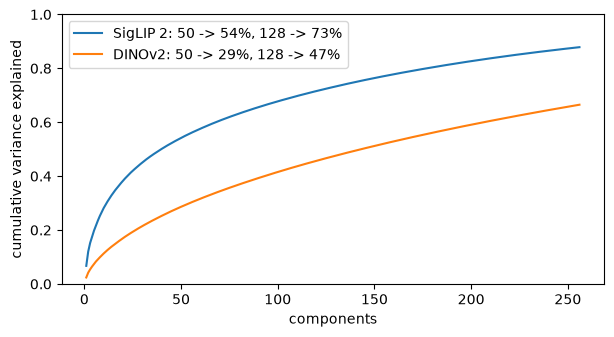

In [2]:
from sklearn.decomposition import PCA

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, block in (("SigLIP 2", features.siglip), ("DINOv2", features.dinov2)):
    pca = PCA(n_components=256, random_state=0).fit(block[np.random.default_rng(0).choice(len(block), 20_000, replace=False)])
    cumulative = np.cumsum(pca.explained_variance_ratio_)
    ax.plot(np.arange(1, 257), cumulative, label=f"{name}: 50 -> {cumulative[49]:.0%}, 128 -> {cumulative[127]:.0%}")
ax.set(xlabel="components", ylabel="cumulative variance explained", ylim=(0, 1))
ax.legend()

SigLIP 2's variance is concentrated in fewer directions than DINOv2's, which spreads over many more. That is why 128 components keep about 73% for SigLIP and under half for DINOv2 (DECISIONS #17).

## 2 · The two maps

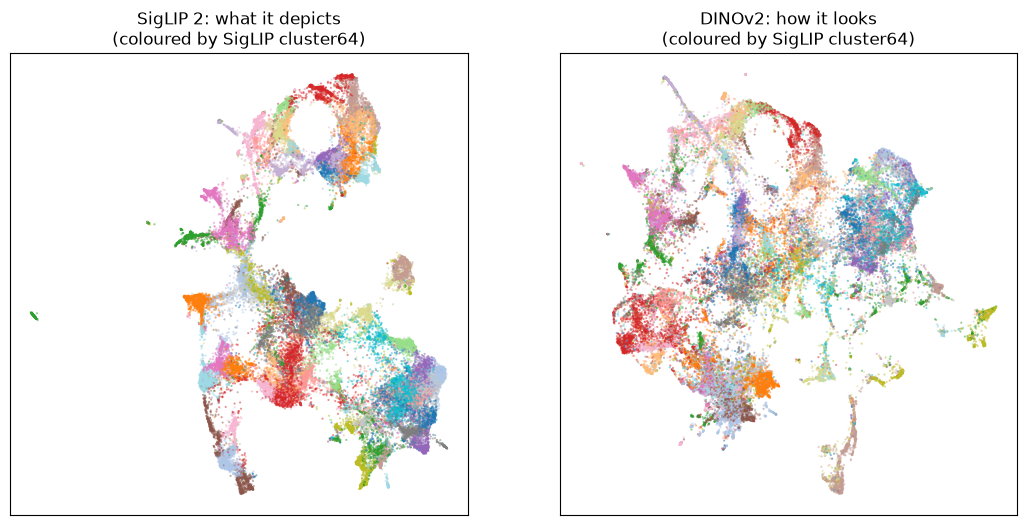

In [3]:
from visualtaste.viz.projection import load_coords

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, key, title in zip(axes, ("siglip2_b16_224", "dinov2_b14"), ("SigLIP 2: what it depicts", "DINOv2: how it looks")):
    ids, coords = load_coords(state.settings.features_dir, key)
    rows = features.positions(ids)
    ax.scatter(coords[:, 0], coords[:, 1], s=0.3, c=np.asarray(features.cluster64)[rows], cmap="tab20", alpha=0.5)
    ax.set_title(f"{title}\n(coloured by SigLIP cluster64)"); ax.set_xticks([]); ax.set_yticks([])

Coloured by the *SigLIP* clusters on both maps. On the SigLIP map the colours form clean islands, as they must: the clusters were made in that space. On the DINOv2 map the same colours mix, because two images about the same subject can look nothing alike.

## 3 · Does UMAP keep neighbourhoods?

Trustworthiness (scikit-learn) asks: of each point's nearest neighbours *on the map*, how many were also near in the original space? 1.0 is perfect; a random layout scores about 0.5.

In [4]:
from sklearn.manifold import trustworthiness

ids, coords = load_coords(state.settings.features_dir, "siglip2_b16_224")
rows = features.positions(ids)
sample = np.random.default_rng(0).choice(len(rows), 3_000, replace=False)
print("UMAP trustworthiness (k = 10, 3,000 points):",
      round(trustworthiness(features.siglip[rows[sample]], coords[sample], n_neighbors=10, metric="cosine"), 3))
shuffled = coords[sample][np.random.default_rng(1).permutation(len(sample))]
print("a shuffled layout, for comparison:          ",
      round(trustworthiness(features.siglip[rows[sample]], shuffled, n_neighbors=10, metric="cosine"), 3))

UMAP trustworthiness (k = 10, 3,000 points): 0.95


a shuffled layout, for comparison:           0.499
